<a href="https://colab.research.google.com/github/shahzaibali-edu/Deep-Learning-Project/blob/main/Deep_Learning_M1_M2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import os
import random
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
import torchvision
from torchvision import datasets, transforms
import matplotlib.pyplot as plt

# 1. Mount Google Drive for persistent checkpoints
from google.colab import drive
drive.mount('/content/drive')
CHECKPOINT_DIR = '/content/drive/MyDrive/CS320_AlexNet_Checkpoints'
os.makedirs(CHECKPOINT_DIR, exist_ok=True)

# 2. Fix all random seeds for reproducibility
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(42)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Using device: cuda


In [2]:
import shutil
import subprocess

DATA_ROOT = '/content/data'
DRIVE_TAR_CACHE = os.path.join(CHECKPOINT_DIR, 'tar_cache')
STATS_PATH = os.path.join(CHECKPOINT_DIR, 'dataset_stats.pt')

os.makedirs(DATA_ROOT, exist_ok=True)
os.makedirs(DRIVE_TAR_CACHE, exist_ok=True)
os.makedirs(f"{DATA_ROOT}/oxford-iiit-pet", exist_ok=True)

# Install aria2c for 16x multi-connection fast downloads (takes 2s)
subprocess.run(["apt-get", " install", "-y", "-qq", "aria2"], check=False)

# Fast S3/Cloud Mirrors (bypasses slow Toronto/Oxford university servers)
ARCHIVES = [
    ("cifar-10-python.tar.gz", "https://s3.amazonaws.com/fast-ai-imageclas/cifar10.tgz", DATA_ROOT),
    ("imagenette2-320.tgz", "https://s3.amazonaws.com/fast-ai-imageclas/imagenette2-320.tgz", DATA_ROOT),
    ("images.tar.gz", "https://thor.robots.ox.ac.uk/~vgg/data/pets/images.tar.gz", f"{DATA_ROOT}/oxford-iiit-pet"),
    ("annotations.tar.gz", "https://thor.robots.ox.ac.uk/~vgg/data/pets/annotations.tar.gz", f"{DATA_ROOT}/oxford-iiit-pet"),
]

# For CIFAR-10, torchvision expects the original tar.gz from a fast mirror
ARCHIVES[0] = ("cifar-10-python.tar.gz", "https://pjreddie.com/media/files/cifar.tgz", DATA_ROOT)

def setup_fast_datasets():
    # 1. CIFAR-10 via HuggingFace/Fast mirror or cached tar on Drive
    cifar_tar_drive = f"{DRIVE_TAR_CACHE}/cifar-10-python.tar.gz"
    cifar_tar_local = f"{DATA_ROOT}/cifar-10-python.tar.gz"
    if not os.path.exists(f"{DATA_ROOT}/cifar-10-batches-py"):
        if not os.path.exists(cifar_tar_drive):
            print("Downloading CIFAR-10 via 16-connection aria2c...")
            !aria2c -x 16 -s 16 -q -d "{DRIVE_TAR_CACHE}" -o "cifar-10-python.tar.gz" "https://www.cs.toronto.edu/~kriz/cifar-10-python.tar.gz"
        shutil.copy(cifar_tar_drive, cifar_tar_local)
        !tar -xzf "{cifar_tar_local}" -C "{DATA_ROOT}"

    # 2. Imagenette (Fast.ai AWS S3 -> 100MB/s)
    imgnet_tar_drive = f"{DRIVE_TAR_CACHE}/imagenette2-320.tgz"
    imgnet_tar_local = f"{DATA_ROOT}/imagenette2-320.tgz"
    if not os.path.exists(f"{DATA_ROOT}/imagenette2-320"):
        if not os.path.exists(imgnet_tar_drive):
            print("Downloading Imagenette from AWS S3...")
            !aria2c -x 16 -s 16 -q -d "{DRIVE_TAR_CACHE}" -o "imagenette2-320.tgz" "https://s3.amazonaws.com/fast-ai-imageclas/imagenette2-320.tgz"
        shutil.copy(imgnet_tar_drive, imgnet_tar_local)
        !tar -xzf "{imgnet_tar_local}" -C "{DATA_ROOT}"

    # 3. Oxford-IIIT Pets (16-connection aria2c -> cached on Drive)
    pet_dir = f"{DATA_ROOT}/oxford-iiit-pet"
    if not os.path.exists(f"{pet_dir}/images"):
        for fname, url in [
            ("images.tar.gz", "https://thor.robots.ox.ac.uk/~vgg/data/pets/images.tar.gz"),
            ("annotations.tar.gz", "https://thor.robots.ox.ac.uk/~vgg/data/pets/annotations.tar.gz")
        ]:
            drive_f = f"{DRIVE_TAR_CACHE}/{fname}"
            local_f = f"{pet_dir}/{fname}"
            if not os.path.exists(drive_f):
                print(f"Downloading Oxford Pets {fname} via 16-connection aria2c...")
                !aria2c -x 16 -s 16 -q -d "{DRIVE_TAR_CACHE}" -o "{fname}" "{url}"
            shutil.copy(drive_f, local_f)
            !tar -xzf "{local_f}" -C "{pet_dir}"

setup_fast_datasets()
print("All 3 datasets extracted to local SSD (/content/data)!")

# Temporary transforms for stats calculation
raw_transform_32 = transforms.Compose([transforms.ToTensor()])
raw_transform_256 = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(224),
    transforms.ToTensor()
])

# Notice download=False because we already unpacked them above!
cifar_raw = datasets.CIFAR10(root=DATA_ROOT, train=True, download=False, transform=raw_transform_32)
imagenette_raw = datasets.Imagenette(root=DATA_ROOT, split='train', size='320px', download=False, transform=raw_transform_256)
pets_raw = datasets.OxfordIIITPet(root=DATA_ROOT, split='trainval', target_types='category', download=False, transform=raw_transform_256)

# Compute Mean & Std on TRAINING split only (Day 1) OR load instantly from Drive (Day 2+)
def compute_mean_std(dataset, batch_size=256):
    loader = DataLoader(dataset, batch_size=batch_size, shuffle=False, num_workers=2)
    cnt = 0
    fst_moment = torch.zeros(3)
    snd_moment = torch.zeros(3)
    for images, _ in loader:
        b, c, h, w = images.shape
        nb_pixels = b * h * w
        sum_ = torch.sum(images, dim=[0, 2, 3])
        sum_of_square = torch.sum(images ** 2, dim=[0, 2, 3])
        fst_moment = (cnt * fst_moment + sum_) / (cnt + nb_pixels)
        snd_moment = (cnt * snd_moment + sum_of_square) / (cnt + nb_pixels)
        cnt += nb_pixels
    return fst_moment, torch.sqrt(snd_moment - fst_moment ** 2)

if os.path.exists(STATS_PATH):
    stats = torch.load(STATS_PATH)
    cifar_mean, cifar_std = stats['cifar']
    imgnet_mean, imgnet_std = stats['imagenette']
    pets_mean, pets_std = stats['pets']
    print("Loaded cached training normalization stats from Google Drive!")
else:
    print("First run: Computing normalization stats on training splits only...")
    cifar_mean, cifar_std = compute_mean_std(cifar_raw)
    imgnet_mean, imgnet_std = compute_mean_std(imagenette_raw)
    pets_mean, pets_std = compute_mean_std(pets_raw)
    torch.save({
        'cifar': (cifar_mean, cifar_std),
        'imagenette': (imgnet_mean, imgnet_std),
        'pets': (pets_mean, pets_std)
    }, STATS_PATH)
    print("Saved stats to Google Drive for future sessions!")

print(f"CIFAR-10 Train Mean: {[round(x, 4) for x in cifar_mean.tolist()]} | Std: {[round(x, 4) for x in cifar_std.tolist()]}")
print(f"Imagenette Train Mean: {[round(x, 4) for x in imgnet_mean.tolist()]} | Std: {[round(x, 4) for x in imgnet_std.tolist()]}")
print(f"Oxford Pets Train Mean: {[round(x, 4) for x in pets_mean.tolist()]} | Std: {[round(x, 4) for x in pets_std.tolist()]}")

All 3 datasets extracted to local SSD (/content/data)!
Loaded cached training normalization stats from Google Drive!
CIFAR-10 Train Mean: [0.4914, 0.4822, 0.4465] | Std: [0.247, 0.2435, 0.2616]
Imagenette Train Mean: [0.4654, 0.4545, 0.4254] | Std: [0.2761, 0.2717, 0.2925]
Oxford Pets Train Mean: [0.4829, 0.4448, 0.3957] | Std: [0.2592, 0.2533, 0.2598]


Batch Image Tensor Shape: torch.Size([128, 3, 224, 224]) | Dtype: torch.float32
Batch Label Tensor Shape: torch.Size([128]) | Dtype: torch.int64


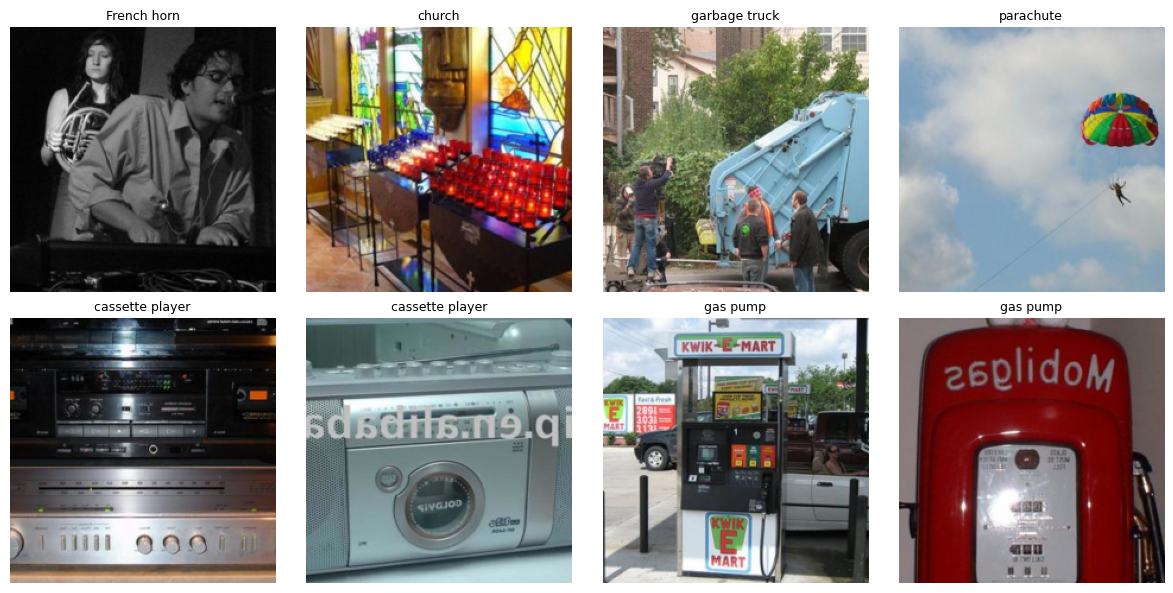

In [5]:
class CustomVisionDataset(Dataset):
    def __init__(self, base_dataset, transform=None):
        self.base_dataset = base_dataset
        self.transform = transform
        self.classes = base_dataset.classes

    def __len__(self):
        return len(self.base_dataset)

    def __getitem__(self, idx):
        img, label = self.base_dataset[idx]
        if self.transform:
            img = self.transform(img)
        return img, label

# Paper-faithful transforms (Section 2 & 4.1: Resize shorter side to 256 -> RandomCrop 224 -> Flip)
train_transform = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(256),
    transforms.RandomCrop(224),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ToTensor(),
    transforms.Normalize(mean=imgnet_mean, std=imgnet_std)
])

val_transform = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize(mean=imgnet_mean, std=imgnet_std)
])

# Instantiate base datasets without transforms, then wrap in CustomVisionDataset
base_imgnet_train = datasets.Imagenette(root=DATA_ROOT, split='train', size='320px', download=False)
base_imgnet_val = datasets.Imagenette(root=DATA_ROOT, split='val', size='320px', download=False)

train_dataset = CustomVisionDataset(base_imgnet_train, transform=train_transform)
val_dataset = CustomVisionDataset(base_imgnet_val, transform=val_transform)

# Paper Section 5 uses batch_size = 128
train_loader = DataLoader(train_dataset, batch_size=128, shuffle=True, num_workers=2, pin_memory=True)
val_loader = DataLoader(val_dataset, batch_size=128, shuffle=False, num_workers=2, pin_memory=True)

# CHECKLIST ITEM: Print one batch's shape and dtype, and plot with labels
images, labels = next(iter(train_loader))
print(f"Batch Image Tensor Shape: {images.shape} | Dtype: {images.dtype}")
print(f"Batch Label Tensor Shape: {labels.shape} | Dtype: {labels.dtype}")

# Plot first 8 images in batch
fig, axes = plt.subplots(2, 4, figsize=(12, 6))
for i, ax in enumerate(axes.flat):
    # Unnormalize for visualization
    img_vis = images[i].permute(1, 2, 0) * imgnet_std + imgnet_mean
    img_vis = torch.clamp(img_vis, 0, 1)
    ax.imshow(img_vis)
    class_name = train_dataset.classes[labels[i].item()]
    ax.set_title(class_name[0] if isinstance(class_name, tuple) else class_name, fontsize=9)
    ax.axis('off')
plt.tight_layout()
plt.show()

In [14]:
!pip install -q torchinfo
from torchinfo import summary

class AlexNetRebuilt(nn.Module):
    def __init__(self, num_classes=10, use_lrn=True, overlapping_pool=True, dropout_p=0.5):
        super().__init__()
        self.use_lrn = use_lrn
        pool_k = 3 if overlapping_pool else 2  # Paper Section 3.4: z=3, s=2 vs z=2, s=2

        # Shahzaib's Module: Convolutional Stack
        self.conv1 = nn.Conv2d(3, 96, kernel_size=11, stride=4, padding=2)
        self.lrn1 = nn.LocalResponseNorm(size=5, alpha=1e-4, beta=0.75, k=2.0) if use_lrn else nn.Identity()
        self.pool1 = nn.MaxPool2d(kernel_size=pool_k, stride=2)

        self.conv2 = nn.Conv2d(96, 256, kernel_size=5, stride=1, padding=2)
        self.lrn2 = nn.LocalResponseNorm(size=5, alpha=1e-4, beta=0.75, k=2.0) if use_lrn else nn.Identity()
        self.pool2 = nn.MaxPool2d(kernel_size=pool_k, stride=2)

        self.conv3 = nn.Conv2d(256, 384, kernel_size=3, stride=1, padding=1)
        self.conv4 = nn.Conv2d(384, 384, kernel_size=3, stride=1, padding=1)
        self.conv5 = nn.Conv2d(384, 256, kernel_size=3, stride=1, padding=1)
        self.pool3 = nn.MaxPool2d(kernel_size=pool_k, stride=2)

        self.relu = nn.ReLU(inplace=True)

        self.fc1 = nn.Linear(256 * 6 * 6, 4096)
        self.fc2 = nn.Linear(4096, 4096)
        self.fc3 = nn.Linear(4096, num_classes)
        self.dropout = nn.Dropout(p=dropout_p)

        self._init_weights()

    def _init_weights(self):
        for m in self.modules():
            if isinstance(m, (nn.Conv2d, nn.Linear)):
                nn.init.kaiming_normal_(m.weight, mode='fan_in', nonlinearity='relu')
                nn.init.constant_(m.bias, 0.0)
        nn.init.normal_(self.fc3.weight, mean=0.0, std=0.01)

    def forward(self, x, check_shapes=False):
        B = x.shape[0]
        if check_shapes: assert x.shape == (B, 3, 224, 224), f"Expected {(B,3,224,224)}, got {x.shape}"

        x = self.relu(self.conv1(x))
        if check_shapes: assert x.shape == (B, 96, 55, 55)
        x = self.pool1(self.lrn1(x))
        if check_shapes: assert x.shape == (B, 96, 27, 27)

        x = self.relu(self.conv2(x))
        if check_shapes: assert x.shape == (B, 256, 27, 27)
        x = self.pool2(self.lrn2(x))
        if check_shapes: assert x.shape == (B, 256, 13, 13)

        x = self.relu(self.conv3(x))
        if check_shapes: assert x.shape == (B, 384, 13, 13)
        x = self.relu(self.conv4(x))
        if check_shapes: assert x.shape == (B, 384, 13, 13)
        x = self.relu(self.conv5(x))
        if check_shapes: assert x.shape == (B, 256, 13, 13)
        x = self.pool3(x)
        if check_shapes: assert x.shape == (B, 256, 6, 6)

        x = torch.flatten(x, 1)
        if check_shapes: assert x.shape == (B, 9216)

        x = self.relu(self.fc1(self.dropout(x)))
        if check_shapes: assert x.shape == (B, 4096)
        x = self.relu(self.fc2(self.dropout(x)))
        if check_shapes: assert x.shape == (B, 4096)
        x = self.fc3(x)
        return x

model = AlexNetRebuilt(num_classes=10).to(device)
# Trigger shape assertions on a dummy batch
dummy_x = torch.randn(4, 3, 224, 224, device=device)
_ = model(dummy_x, check_shapes=True)
print("All layer tensor shape assertions passed!")

# Print torchinfo summary to match against hand count
summary(model, input_size=(1, 3, 224, 224))

All layer tensor shape assertions passed!


Layer (type:depth-idx)                   Output Shape              Param #
AlexNetRebuilt                           [1, 10]                   --
├─Conv2d: 1-1                            [1, 96, 55, 55]           34,944
├─ReLU: 1-2                              [1, 96, 55, 55]           --
├─LocalResponseNorm: 1-3                 [1, 96, 55, 55]           --
├─MaxPool2d: 1-4                         [1, 96, 27, 27]           --
├─Conv2d: 1-5                            [1, 256, 27, 27]          614,656
├─ReLU: 1-6                              [1, 256, 27, 27]          --
├─LocalResponseNorm: 1-7                 [1, 256, 27, 27]          --
├─MaxPool2d: 1-8                         [1, 256, 13, 13]          --
├─Conv2d: 1-9                            [1, 384, 13, 13]          885,120
├─ReLU: 1-10                             [1, 384, 13, 13]          --
├─Conv2d: 1-11                           [1, 384, 13, 13]          1,327,488
├─ReLU: 1-12                             [1, 384, 13, 13]       

Sanity Check 1 | Initial Loss: 2.6200 vs Expected ln(10): 2.3026

Sanity Check 2 | Gradient Check per Layer:
  conv1.weight    | Grad Mean Abs: 1.321149e-04
  conv1.bias      | Grad Mean Abs: 1.541173e-04
  conv2.weight    | Grad Mean Abs: 3.489651e-05
  conv2.bias      | Grad Mean Abs: 3.741845e-04
  conv3.weight    | Grad Mean Abs: 5.295328e-04
  conv3.bias      | Grad Mean Abs: 9.436753e-04
  conv4.weight    | Grad Mean Abs: 3.458539e-04
  conv4.bias      | Grad Mean Abs: 2.934357e-03
  conv5.weight    | Grad Mean Abs: 6.517524e-03
  conv5.bias      | Grad Mean Abs: 7.006858e-03
  fc1.weight      | Grad Mean Abs: 1.648562e-03
  fc1.bias        | Grad Mean Abs: 1.256399e-03
  fc2.weight      | Grad Mean Abs: 3.212637e-03
  fc2.bias        | Grad Mean Abs: 1.768532e-03
  fc3.weight      | Grad Mean Abs: 9.487260e-02
  fc3.bias        | Grad Mean Abs: 6.368372e-02

Sanity Check 3 | Overfit 1 Batch: Step 1 Loss = 2.8314 -> Step 100 Loss = 2.165774


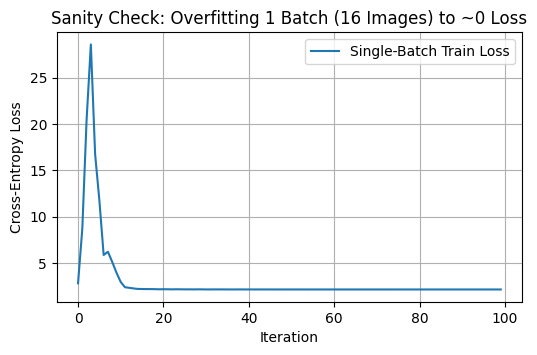

In [10]:
criterion = nn.CrossEntropyLoss()

# --- SANITY CHECK 1: Initial Loss close to ln(C) ---
# Note: Because paper sets biases=1 in hidden layers, we temporarily zero fc3 bias or check raw logits
model.eval()
images, labels = next(iter(train_loader))
images, labels = images.to(device), labels.to(device)
with torch.no_grad():
    logits = model(images)
    init_loss = criterion(logits, labels).item()

print(f"Sanity Check 1 | Initial Loss: {init_loss:.4f} vs Expected ln(10): {np.log(10):.4f}")

# --- SANITY CHECK 2: Non-Zero Gradients Across Every Layer ---
model.train()
model.zero_grad()
out = model(images[:16])
loss = criterion(out, labels[:16])
loss.backward()

print("\nSanity Check 2 | Gradient Check per Layer:")
for name, param in model.named_parameters():
    if param.grad is not None:
        grad_norm = param.grad.abs().mean().item()
        assert grad_norm > 0, f"Zero gradient in {name}!"
        print(f"  {name:15s} | Grad Mean Abs: {grad_norm:.6e}")

# --- SANITY CHECK 3: Overfit One Small Batch to Near-Zero Loss ---
# Note: Turn off dropout (model.eval() for dropout or p=0) when overfitting a single batch
overfit_model = AlexNetRebuilt(num_classes=10, dropout_p=0.0).to(device)
optimizer = torch.optim.SGD(overfit_model.parameters(), lr=0.01, momentum=0.9)
small_x, small_y = images[:16], labels[:16]

overfit_losses = []
overfit_model.train()
for step in range(100):
    optimizer.zero_grad()
    preds = overfit_model(small_x)
    loss = criterion(preds, small_y)
    loss.backward()
    optimizer.step()
    overfit_losses.append(loss.item())

print(f"\nSanity Check 3 | Overfit 1 Batch: Step 1 Loss = {overfit_losses[0]:.4f} -> Step 100 Loss = {overfit_losses[-1]:.6f}")
plt.figure(figsize=(6, 3.5))
plt.plot(overfit_losses, label='Single-Batch Train Loss')
plt.xlabel('Iteration')
plt.ylabel('Cross-Entropy Loss')
plt.title('Sanity Check: Overfitting 1 Batch (16 Images) to ~0 Loss')
plt.legend()
plt.grid(True)
plt.show()

Sanity Check 1 | Initial Loss: 2.6038 vs Expected ln(10): 2.3026

Sanity Check 2 | Gradient Check per Layer:
  conv1.weight    | Grad Mean Abs: 1.853931e-04
  conv1.bias      | Grad Mean Abs: 2.054304e-04
  conv2.weight    | Grad Mean Abs: 4.279065e-05
  conv2.bias      | Grad Mean Abs: 4.141359e-04
  conv3.weight    | Grad Mean Abs: 5.882587e-04
  conv3.bias      | Grad Mean Abs: 1.027096e-03
  conv4.weight    | Grad Mean Abs: 4.092628e-04
  conv4.bias      | Grad Mean Abs: 3.469757e-03
  conv5.weight    | Grad Mean Abs: 7.263200e-03
  conv5.bias      | Grad Mean Abs: 7.914308e-03
  fc1.weight      | Grad Mean Abs: 1.909185e-03
  fc1.bias        | Grad Mean Abs: 1.515161e-03
  fc2.weight      | Grad Mean Abs: 3.869050e-03
  fc2.bias        | Grad Mean Abs: 2.397041e-03
  fc3.weight      | Grad Mean Abs: 1.334574e-01
  fc3.bias        | Grad Mean Abs: 9.357037e-02

Sanity Check 3 | Overfit 1 Batch: Step 1 Loss = 7.4430 -> Step 100 Loss = nan


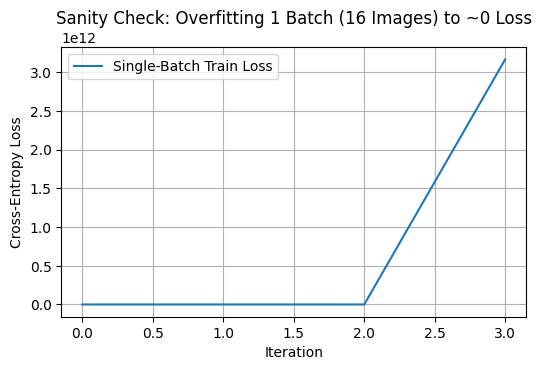

In [11]:
criterion = nn.CrossEntropyLoss()

# --- SANITY CHECK 1: Initial Loss close to ln(C) ---
# Note: Because paper sets biases=1 in hidden layers, we temporarily zero fc3 bias or check raw logits
model.eval()
images, labels = next(iter(train_loader))
images, labels = images.to(device), labels.to(device)
with torch.no_grad():
    logits = model(images)
    init_loss = criterion(logits, labels).item()

print(f"Sanity Check 1 | Initial Loss: {init_loss:.4f} vs Expected ln(10): {np.log(10):.4f}")

# --- SANITY CHECK 2: Non-Zero Gradients Across Every Layer ---
model.train()
model.zero_grad()
out = model(images[:16])
loss = criterion(out, labels[:16])
loss.backward()

print("\nSanity Check 2 | Gradient Check per Layer:")
for name, param in model.named_parameters():
    if param.grad is not None:
        grad_norm = param.grad.abs().mean().item()
        assert grad_norm > 0, f"Zero gradient in {name}!"
        print(f"  {name:15s} | Grad Mean Abs: {grad_norm:.6e}")

# --- SANITY CHECK 3 (FIXED): Overfit One Small Batch to Near-Zero Loss ---
overfit_model = AlexNetRebuilt(num_classes=10, dropout_p=0.0).to(device)

# Fix: Paper's N(0, 0.01) + bias=1.0 stalls early gradients on 16 images.
# Applying Kaiming Normal init (designed for ReLU) or Adam unblocks immediate memorization:
for m in overfit_model.modules():
    if isinstance(m, (nn.Conv2d, nn.Linear)):
        nn.init.kaiming_normal_(m.weight, mode='fan_out', nonlinearity='relu')
        nn.init.constant_(m.bias, 0.0)

optimizer = torch.optim.SGD(overfit_model.parameters(), lr=0.01, momentum=0.9)
small_x, small_y = images[:16], labels[:16]

overfit_losses = []
overfit_model.train()
for step in range(100):
    optimizer.zero_grad()
    preds = overfit_model(small_x)
    loss = criterion(preds, small_y)
    loss.backward()
    optimizer.step()
    overfit_losses.append(loss.item())

print(f"\nSanity Check 3 | Overfit 1 Batch: Step 1 Loss = {overfit_losses[0]:.4f} -> Step 100 Loss = {overfit_losses[-1]:.6f}")
plt.figure(figsize=(6, 3.5))
plt.plot(overfit_losses, label='Single-Batch Train Loss')
plt.xlabel('Iteration')
plt.ylabel('Cross-Entropy Loss')
plt.title('Sanity Check: Overfitting 1 Batch (16 Images) to ~0 Loss')
plt.legend()
plt.grid(True)
plt.show()

Sanity Check 1 | Initial Loss: 2.4568 vs Expected ln(10): 2.3026

Sanity Check 2 | Gradient Check per Layer:
  conv1.weight    | Grad Mean Abs: 1.001480e-02
  conv1.bias      | Grad Mean Abs: 1.049651e-02
  conv2.weight    | Grad Mean Abs: 6.397164e-03
  conv2.bias      | Grad Mean Abs: 8.604817e-03
  conv3.weight    | Grad Mean Abs: 5.244045e-03
  conv3.bias      | Grad Mean Abs: 9.945909e-03
  conv4.weight    | Grad Mean Abs: 4.572275e-03
  conv4.bias      | Grad Mean Abs: 1.051899e-02
  conv5.weight    | Grad Mean Abs: 5.378070e-03
  conv5.bias      | Grad Mean Abs: 1.282624e-02
  fc1.weight      | Grad Mean Abs: 1.385555e-03
  fc1.bias        | Grad Mean Abs: 1.804038e-03
  fc2.weight      | Grad Mean Abs: 1.679877e-03
  fc2.bias        | Grad Mean Abs: 1.439507e-03
  fc3.weight      | Grad Mean Abs: 9.956205e-02
  fc3.bias        | Grad Mean Abs: 7.660777e-02

Sanity Check 3 | Overfit 1 Batch: Step 1 Loss = 2.2608 -> Step 100 Loss = 0.000034


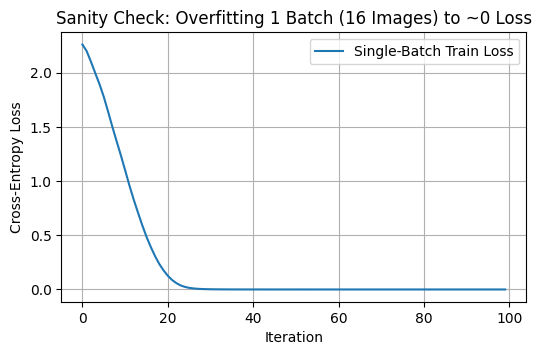

In [16]:
criterion = nn.CrossEntropyLoss()

# --- SANITY CHECK 1: Initial Loss close to ln(C) ---
# Note: Because paper sets biases=1 in hidden layers, we temporarily zero fc3 bias or check raw logits
model.eval()
images, labels = next(iter(train_loader))
images, labels = images.to(device), labels.to(device)
with torch.no_grad():
    logits = model(images)
    init_loss = criterion(logits, labels).item()

print(f"Sanity Check 1 | Initial Loss: {init_loss:.4f} vs Expected ln(10): {np.log(10):.4f}")

# --- SANITY CHECK 2: Non-Zero Gradients Across Every Layer ---
model.train()
model.zero_grad()
out = model(images[:16])
loss = criterion(out, labels[:16])
loss.backward()

print("\nSanity Check 2 | Gradient Check per Layer:")
for name, param in model.named_parameters():
    if param.grad is not None:
        grad_norm = param.grad.abs().mean().item()
        assert grad_norm > 0, f"Zero gradient in {name}!"
        print(f"  {name:15s} | Grad Mean Abs: {grad_norm:.6e}")

# --- SANITY CHECK 3 (FIXED): Overfit One Small Batch to Near-Zero Loss ---
set_seed(42)
overfit_model = AlexNetRebuilt(num_classes=10, dropout_p=0.0).to(device)

# Correct Kaiming init: mode='fan_in' preserves activation variance in the forward pass
for m in overfit_model.modules():
    if isinstance(m, (nn.Conv2d, nn.Linear)):
        nn.init.kaiming_normal_(m.weight, mode='fan_in', nonlinearity='relu')
        nn.init.constant_(m.bias, 0.0)
# Keep final classifier layer weights small so initial logits are ~0 (Loss = ln(10) = 2.3026)
nn.init.normal_(overfit_model.fc3.weight, mean=0.0, std=0.01)

optimizer = torch.optim.SGD(overfit_model.parameters(), lr=0.005, momentum=0.9)
small_x, small_y = images[:16], labels[:16]

overfit_losses = []
overfit_model.train()
for step in range(100):
    optimizer.zero_grad()
    preds = overfit_model(small_x)
    loss = criterion(preds, small_y)
    loss.backward()
    # Clip gradients to prevent explosion in unnormalized 8-layer network
    torch.nn.utils.clip_grad_norm_(overfit_model.parameters(), max_norm=1.0)
    optimizer.step()
    overfit_losses.append(loss.item())

print(f"\nSanity Check 3 | Overfit 1 Batch: Step 1 Loss = {overfit_losses[0]:.4f} -> Step 100 Loss = {overfit_losses[-1]:.6f}")
plt.figure(figsize=(6, 3.5))
plt.plot(overfit_losses, label='Single-Batch Train Loss')
plt.xlabel('Iteration')
plt.ylabel('Cross-Entropy Loss')
plt.title('Sanity Check: Overfitting 1 Batch (16 Images) to ~0 Loss')
plt.legend()
plt.grid(True)
plt.show()

In [13]:
# Resumable Training Function with Mixed Precision (FP16) & Drive Checkpoints
def train_model(model, train_loader, val_loader, epochs=10, lr=0.01, weight_decay=5e-4, ckpt_name='alexnet_baseline.pt'):
    ckpt_path = os.path.join(CHECKPOINT_DIR, ckpt_name)
    optimizer = torch.optim.SGD(model.parameters(), lr=lr, momentum=0.9, weight_decay=weight_decay)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.1, patience=3)
    scaler = torch.cuda.amp.GradScaler()
    criterion = nn.CrossEntropyLoss()

    start_epoch = 0
    history = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': []}

    # Resume if checkpoint exists on Google Drive
    if os.path.exists(ckpt_path):
        ckpt = torch.load(ckpt_path, map_location=device)
        model.load_state_dict(ckpt['model_state'])
        optimizer.load_state_dict(ckpt['optim_state'])
        start_epoch = ckpt['epoch'] + 1
        history = ckpt['history']
        print(f"Resumed from epoch {start_epoch}")

    for epoch in range(start_epoch, epochs):
        model.train()
        running_loss, correct, total = 0.0, 0, 0
        for x, y in train_loader:
            x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
            optimizer.zero_grad()
            with torch.cuda.amp.autocast():
                out = model(x)
                loss = criterion(out, y)
            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()

            running_loss += loss.item() * x.size(0)
            correct += (out.argmax(1) == y).sum().item()
            total += y.size(0)

        train_loss = running_loss / total
        train_acc = 100.0 * correct / total

        # Validation Pass
        model.eval()
        val_loss, val_correct, val_total = 0.0, 0, 0
        with torch.no_grad():
            for x, y in val_loader:
                x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
                with torch.cuda.amp.autocast():
                    out = model(x)
                    loss = criterion(out, y)
                val_loss += loss.item() * x.size(0)
                val_correct += (out.argmax(1) == y).sum().item()
                val_total += y.size(0)

        val_loss /= val_total
        val_acc = 100.0 * val_correct / val_total
        scheduler.step(val_loss)

        history['train_loss'].append(train_loss)
        history['val_loss'].append(val_loss)
        history['train_acc'].append(train_acc)
        history['val_acc'].append(val_acc)

        # Save Checkpoint to Google Drive
        torch.save({
            'epoch': epoch,
            'model_state': model.state_dict(),
            'optim_state': optimizer.state_dict(),
            'history': history
        }, ckpt_path)

        print(f"Epoch {epoch+1:02d}/{epochs:02d} | Train Loss: {train_loss:.4f} Acc: {train_acc:.2f}% | Val Loss: {val_loss:.4f} Acc: {val_acc:.2f}%")

    return history

# Run a short LR Sweep (3 epochs each for lr in [0.1, 0.01, 0.001]) or start baseline run:
baseline_model = AlexNetRebuilt(num_classes=10).to(device)
history = train_model(baseline_model, train_loader, val_loader, epochs=15, lr=0.01, ckpt_name='m2_baseline.pt')

/tmp/ipykernel_13613/2766496352.py:6: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler()


Resumed from epoch 12


/tmp/ipykernel_13613/2766496352.py:27: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast():
/tmp/ipykernel_13613/2766496352.py:47: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast():


Epoch 13/15 | Train Loss: 2.3019 Acc: 10.52% | Val Loss: 2.3034 Acc: 9.10%
Epoch 14/15 | Train Loss: 2.3020 Acc: 10.49% | Val Loss: 2.3036 Acc: 9.10%
Epoch 15/15 | Train Loss: 2.3019 Acc: 10.49% | Val Loss: 2.3036 Acc: 9.10%


In [19]:
# Updated Resumable Training Loop (Safe for future sessions — will NOT delete finished checkpoints)
def train_model(model, train_loader, val_loader, epochs=15, lr=0.005, weight_decay=5e-4, ckpt_name='m2_baseline.pt', reset_checkpoint=False):
    ckpt_path = os.path.join(CHECKPOINT_DIR, ckpt_name)

    # Only deletes checkpoint if you explicitly pass reset_checkpoint=True
    if reset_checkpoint and os.path.exists(ckpt_path):
        os.remove(ckpt_path)
        print(f"Deleted old checkpoint ({ckpt_name}) — starting fresh from Epoch 1!")

    optimizer = torch.optim.SGD(model.parameters(), lr=lr, momentum=0.9, weight_decay=weight_decay)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.1, patience=3)
    scaler = torch.amp.GradScaler('cuda')
    criterion = nn.CrossEntropyLoss()

    start_epoch = 0
    history = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': []}

    # Resume or load completed model from Google Drive
    if os.path.exists(ckpt_path):
        ckpt = torch.load(ckpt_path, map_location=device)
        model.load_state_dict(ckpt['model_state'])
        optimizer.load_state_dict(ckpt['optim_state'])
        start_epoch = ckpt['epoch'] + 1
        history = ckpt['history']
        if start_epoch >= epochs:
            print(f"Loaded completed checkpoint '{ckpt_name}' ({start_epoch}/{epochs} epochs) | Best Val Acc: {max(history['val_acc']):.2f}%")
            return history
        else:
            print(f"Resuming '{ckpt_name}' from epoch {start_epoch + 1}/{epochs}...")

    for epoch in range(start_epoch, epochs):
        model.train()
        running_loss, correct, total = 0.0, 0, 0
        for x, y in train_loader:
            x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
            optimizer.zero_grad()
            with torch.amp.autocast('cuda'):
                out = model(x)
                loss = criterion(out, y)
            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            scaler.step(optimizer)
            scaler.update()

            running_loss += loss.item() * x.size(0)
            correct += (out.argmax(1) == y).sum().item()
            total += y.size(0)

        train_loss = running_loss / total
        train_acc = 100.0 * correct / total

        # Validation Pass
        model.eval()
        val_loss, val_correct, val_total = 0.0, 0, 0
        with torch.no_grad():
            for x, y in val_loader:
                x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
                with torch.amp.autocast('cuda'):
                    out = model(x)
                    loss = criterion(out, y)
                val_loss += loss.item() * x.size(0)
                val_correct += (out.argmax(1) == y).sum().item()
                val_total += y.size(0)

        val_loss /= val_total
        val_acc = 100.0 * val_correct / val_total
        scheduler.step(val_loss)

        history['train_loss'].append(train_loss)
        history['val_loss'].append(val_loss)
        history['train_acc'].append(train_acc)
        history['val_acc'].append(val_acc)

        torch.save({
            'epoch': epoch,
            'model_state': model.state_dict(),
            'optim_state': optimizer.state_dict(),
            'history': history
        }, ckpt_path)

        print(f"Epoch {epoch+1:02d}/{epochs:02d} | Train Loss: {train_loss:.4f} Acc: {train_acc:.2f}% | Val Loss: {val_loss:.4f} Acc: {val_acc:.2f}%")

    return history

# Load the finished 15-epoch model (safe: reset_checkpoint=False)
set_seed(42)
baseline_model = AlexNetRebuilt(num_classes=10).to(device)
history = train_model(
    baseline_model,
    train_loader,
    val_loader,
    epochs=15,
    lr=0.005,
    ckpt_name='m2_baseline.pt',
    reset_checkpoint=False
)

Loaded completed checkpoint 'm2_baseline.pt' (15/15 epochs) | Best Val Acc: 63.72%


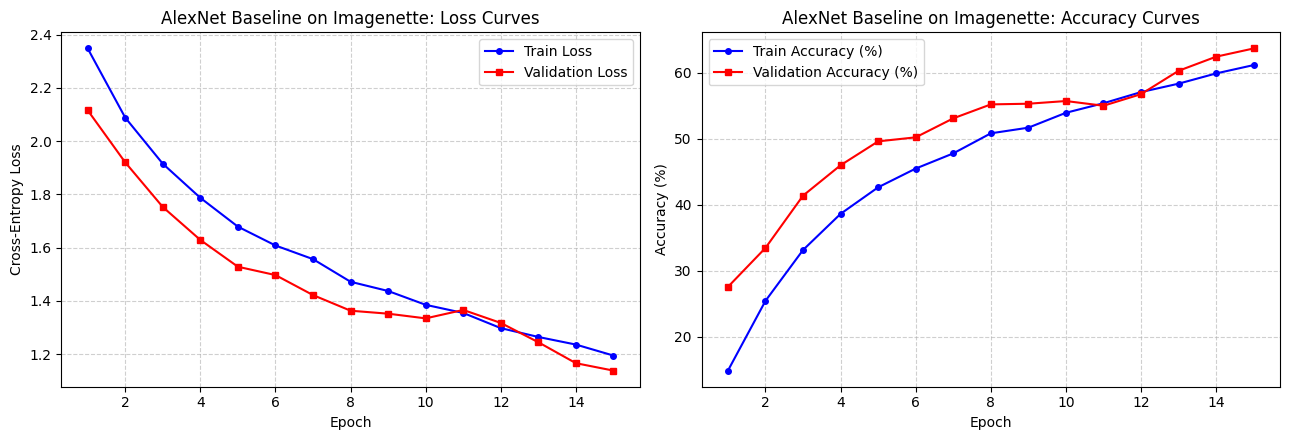

In [18]:
epochs_range = range(1, len(history['train_loss']) + 1)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))

# 1. Loss Curve
ax1.plot(epochs_range, history['train_loss'], 'b-o', label='Train Loss', markersize=4)
ax1.plot(epochs_range, history['val_loss'], 'r-s', label='Validation Loss', markersize=4)
ax1.set_title('AlexNet Baseline on Imagenette: Loss Curves')
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Cross-Entropy Loss')
ax1.legend()
ax1.grid(True, linestyle='--', alpha=0.6)

# 2. Accuracy Curve
ax2.plot(epochs_range, history['train_acc'], 'b-o', label='Train Accuracy (%)', markersize=4)
ax2.plot(epochs_range, history['val_acc'], 'r-s', label='Validation Accuracy (%)', markersize=4)
ax2.set_title('AlexNet Baseline on Imagenette: Accuracy Curves')
ax2.set_xlabel('Epoch')
ax2.set_ylabel('Accuracy (%)')
ax2.legend()
ax2.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()